# LARRY curvature region 1 acceleration

Current FlowMap package version of the LARRY curvature analysis. Legacy curvature calls are replaced by `flowmap.geometry.compute_flow_curvature`; plots are saved under `figures/larry`.

In [1]:
from pathlib import Path
import os
import sys

NOTEBOOK_DIR = Path.cwd()
FIG_DIR = NOTEBOOK_DIR / "figures" / "larry"
FIG_DIR.mkdir(parents=True, exist_ok=True)

os.environ.setdefault("NUMBA_CACHE_DIR", str((NOTEBOOK_DIR / ".numba_cache").resolve()))
os.environ.setdefault("MPLCONFIGDIR", str((NOTEBOOK_DIR / ".mpl_cache").resolve()))

LOCAL_FLOWMAP_SRC = Path("/Users/jh/Projects/flowmap/src")
if LOCAL_FLOWMAP_SRC.exists() and str(LOCAL_FLOWMAP_SRC) not in sys.path:
    sys.path.insert(0, str(LOCAL_FLOWMAP_SRC))

DATA_PATH = (NOTEBOOK_DIR / "../data/flowmap_manuscript/larry/tutorial_larry_flowmap_data.joblib").resolve()
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Put the tutorial_larry_flowmap_data.joblib source data file there before running."
    )

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from sklearn.neighbors import NearestNeighbors

from flowmap.geometry import compute_flow_curvature
from flowmap.plot import plot_velocity_stream
from flowmap.utils import load_dataset

data = load_dataset(DATA_PATH)
emb = data.embedder
labels = data.obs["state_info"].astype(str).to_numpy()
gene_names = np.asarray(data.var_names)
X_gene = data.layers["spliced"]

curv = compute_flow_curvature(emb)
coords = emb.X_emb

k_total = curv["curvature"]["total"]
k_steer = curv["curvature"]["steer"]
k_surface = curv["curvature"]["surface"]

A_flow = np.linalg.norm(curv["acceleration"]["flow"], axis=1)
A_steer = np.linalg.norm(curv["acceleration"]["steer"], axis=1)
A_surface = np.linalg.norm(curv["acceleration"]["surface"], axis=1)
A_total = A_flow + A_steer + A_surface + 1e-12

flow_frac = A_flow / A_total
steer_frac = A_steer / A_total
surface_frac = A_surface / A_total

print(data)
print("Curvature keys:", curv.keys())

Matplotlib is building the font cache; this may take a moment.
/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FlowMapDataset object with n_obs x n_features = 49302 x 2000
    X: (49302, 2000), V: (49302, 2000)
    embedder: VectorFieldEmbedder
    obs: 'state_info', 'time_info'
    layers: 'spliced', 'velocity'
    obsm: 'X_flowmap', 'V_flowmap'
    metadata: 'schema_version', 'source_format', 'name', 'description'
Curvature keys: dict_keys(['velocity', 'acceleration', 'curvature'])


In [3]:
def clipped(values, q=99):
    hi = np.nanpercentile(values, q)
    return np.clip(values, None, hi)


def plot_component_panels(filename, title_prefix=""):
    panels = [
        ("total", k_total, "coolwarm"),
        ("steering", k_steer, "magma"),
        ("surface", k_surface, "viridis"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, (name, values, cmap) in zip(axes, panels):
        plot_velocity_stream(
            emb.X_emb,
            spline=emb.spline_vf,
            scatter_color=clipped(values),
            cmap=cmap,
            scatter_size=8,
            scatter_alpha=0.65,
            show_colorbar=True,
            ax=ax,
        )
        ax.set_title(f"{title_prefix}{name} curvature")
        ax.set_aspect("equal")
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    return fig, axes


def plot_total_curvature(filename, title="Total curvature"):
    fig, ax = plt.subplots(figsize=(7, 7))
    plot_velocity_stream(
        emb.X_emb,
        spline=emb.spline_vf,
        scatter_color=clipped(k_total),
        cmap="coolwarm",
        scatter_size=8,
        scatter_alpha=0.65,
        show_colorbar=True,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_aspect("equal")
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    return fig, ax


def plot_acceleration_triangle(filename):
    x = steer_frac + 0.5 * surface_frac
    y = (np.sqrt(3) / 2) * surface_frac
    fig, ax = plt.subplots(figsize=(6, 5.5))
    sc = ax.scatter(x, y, c=clipped(k_total), s=5, cmap="coolwarm", alpha=0.55, linewidths=0)
    tri = np.array([[0, 0], [1, 0], [0.5, np.sqrt(3) / 2], [0, 0]])
    ax.plot(tri[:, 0], tri[:, 1], c="black", lw=1)
    ax.text(-0.04, -0.04, "flow", ha="right", va="top")
    ax.text(1.04, -0.04, "steer", ha="left", va="top")
    ax.text(0.5, np.sqrt(3) / 2 + 0.04, "surface", ha="center", va="bottom")
    ax.set_aspect("equal")
    ax.set_axis_off()
    fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.03, label="total curvature")
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    return fig, ax


def zoom_mask(bounds):
    x_min, x_max, y_min, y_max = bounds
    return (
        (coords[:, 0] > x_min) & (coords[:, 0] < x_max) &
        (coords[:, 1] > y_min) & (coords[:, 1] < y_max)
    )


def grow_clusters(local_coords, local_values, seed_points, k=5, quantile=0.55, boundary_fn=None):
    if len(local_coords) == 0:
        return np.array([], dtype=int)
    seeds = np.asarray(seed_points)
    seed_side = None if boundary_fn is None else np.sign([boundary_fn(p) for p in seeds])
    active = local_values >= np.nanquantile(local_values, quantile)
    labels_local = np.full(local_coords.shape[0], -1, dtype=int)
    if not np.any(active):
        return labels_local
    d_seed = np.linalg.norm(local_coords[:, None, :] - seeds[None, :, :], axis=2)
    nearest_seed = np.argmin(d_seed, axis=1)
    if boundary_fn is not None:
        point_side = np.sign([boundary_fn(p) for p in local_coords])
        for i in range(len(local_coords)):
            blocked = seed_side != point_side[i]
            d_seed[i, blocked] = np.inf
        nearest_seed = np.argmin(d_seed, axis=1)
    labels_local[active] = nearest_seed[active]
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(local_coords))).fit(local_coords)
    neigh = nn.kneighbors(return_distance=False)
    changed = True
    while changed:
        changed = False
        for i in np.where(labels_local == -1)[0]:
            neighbor_labels = labels_local[neigh[i]]
            neighbor_labels = neighbor_labels[neighbor_labels >= 0]
            if len(neighbor_labels) == 0:
                continue
            labels_local[i] = np.bincount(neighbor_labels).argmax()
            changed = True
    return labels_local


def plot_zoom_region(bounds, seed_points, filename, title, cluster_k=5, cluster_quantile=0.55, boundary_fn=None):
    mask = zoom_mask(bounds)
    local_coords = coords[mask]
    local_values = k_steer[mask]
    local_labels = grow_clusters(
        local_coords,
        local_values,
        seed_points,
        k=cluster_k,
        quantile=cluster_quantile,
        boundary_fn=boundary_fn,
    )
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    sc = axes[0].scatter(local_coords[:, 0], local_coords[:, 1], c=clipped(local_values), s=18, cmap="magma", alpha=0.8, linewidths=0)
    axes[0].scatter(np.asarray(seed_points)[:, 0], np.asarray(seed_points)[:, 1], marker="x", c="black", s=120, linewidths=2)
    axes[0].set_title(f"{title}: steering curvature")
    fig.colorbar(sc, ax=axes[0], fraction=0.046, pad=0.04)
    assigned = local_labels >= 0
    axes[1].scatter(local_coords[~assigned, 0], local_coords[~assigned, 1], c="lightgray", s=12, alpha=0.35, linewidths=0)
    axes[1].scatter(local_coords[assigned, 0], local_coords[assigned, 1], c=local_labels[assigned], cmap="tab10", s=18, alpha=0.85, linewidths=0)
    axes[1].scatter(np.asarray(seed_points)[:, 0], np.asarray(seed_points)[:, 1], marker="x", c="black", s=120, linewidths=2)
    axes[1].set_title(f"{title}: local regions")
    for ax in axes:
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    local_df = pd.DataFrame({
        "x": local_coords[:, 0],
        "y": local_coords[:, 1],
        "steer_curvature": local_values,
        "cluster": local_labels,
    })
    local_df.to_csv(FIG_DIR / filename.replace(".png", "_cells.csv"), index=False)
    return fig, axes, local_df


def get_gene_vector(matrix, idx):
    col = matrix[:, idx]
    if hasattr(col, "toarray"):
        return np.asarray(col.toarray()).ravel()
    return np.asarray(col).ravel()

def plot_zoom_gene_strip(bounds, genes, filename):
    mask = zoom_mask(bounds)
    valid = [g for g in genes if g in gene_names]
    if not valid:
        print("No requested genes found.")
        return None, None
    fig, axes = plt.subplots(1, len(valid), figsize=(3.5 * len(valid), 3.5), squeeze=False)
    for ax, gene in zip(axes.ravel(), valid):
        gi = int(np.where(gene_names == gene)[0][0])
        vals = get_gene_vector(X_gene, gi)
        ax.scatter(coords[mask, 0], coords[mask, 1], c=vals[mask], cmap="magma_r", s=20, alpha=0.75, linewidths=0)
        ax.set_title(gene)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    return fig, axes

(<Figure size 600x550 with 2 Axes>, <Axes: >)

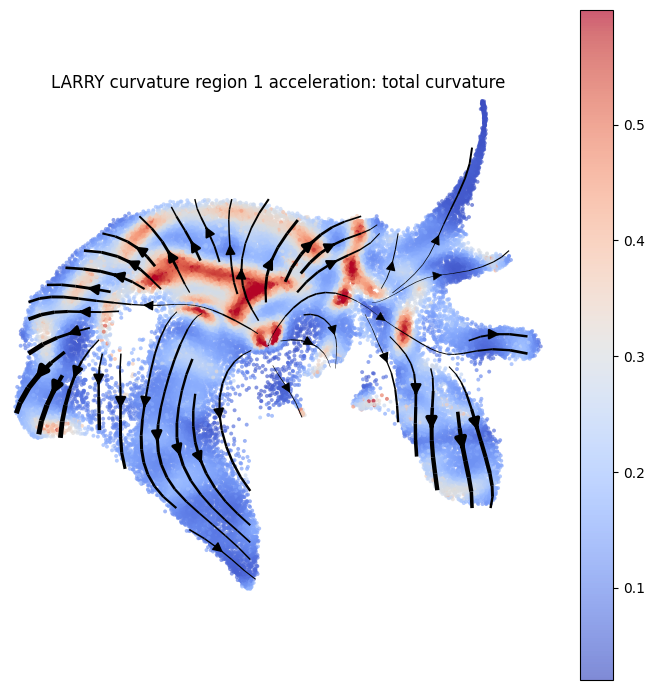

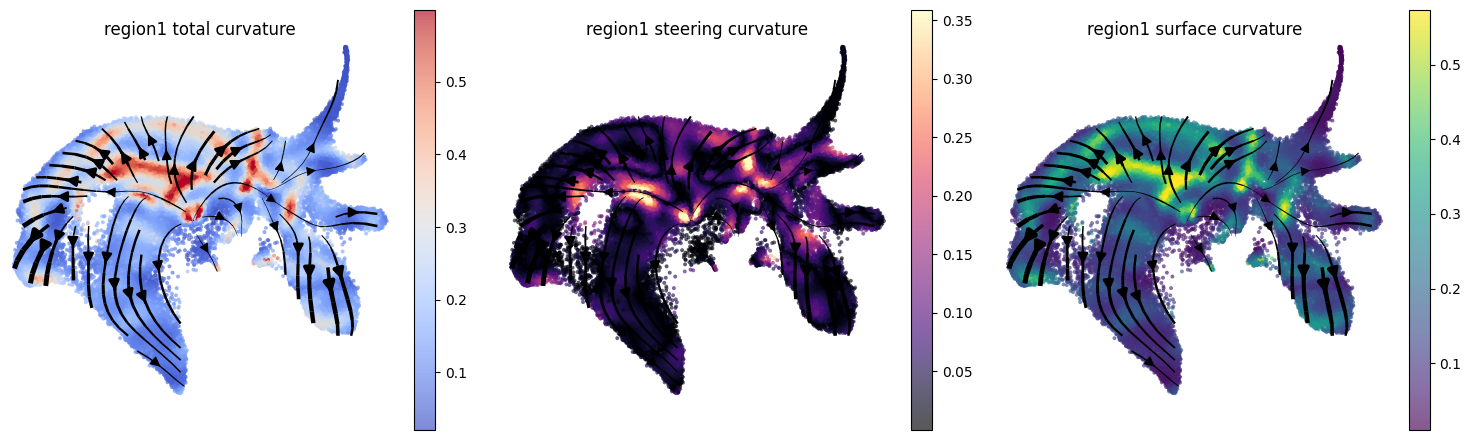

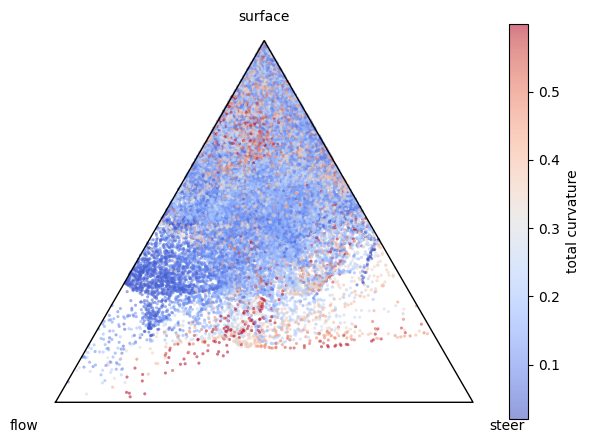

In [4]:
plot_total_curvature("region1_total_curvature.png", title="LARRY curvature region 1 acceleration: total curvature")
plot_component_panels("region1_curvature_components.png", title_prefix="region1 ")
plot_acceleration_triangle("region1_acceleration_triangle.png")

,x,y,steer_curvature,cluster
0,2.761495,3.705045,0.205809,0
1,1.860319,3.941074,0.051511,0
2,2.781803,5.415227,0.050370,1
3,4.338815,4.620825,0.068565,1
4,2.510273,5.366325,0.011993,1


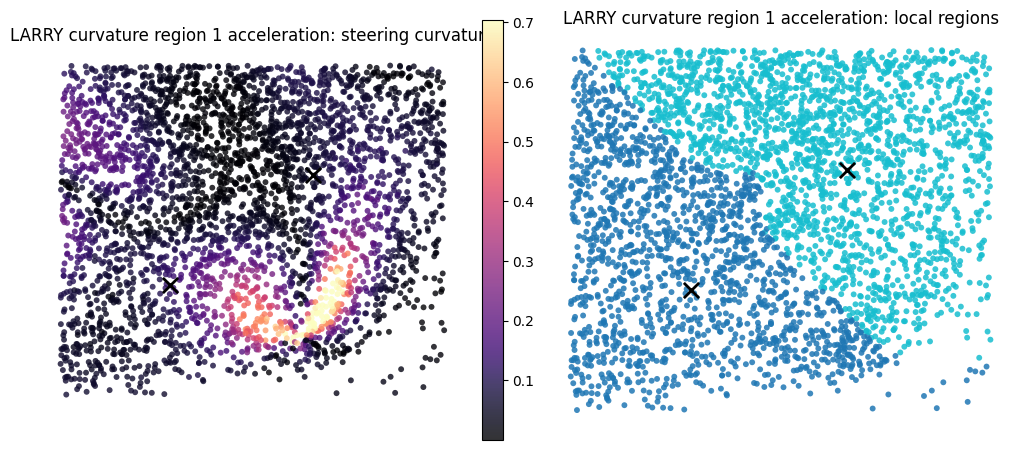

In [5]:
def region_boundary(pt):
    return (pt[0] + pt[1]) - 6.6

REGION_BOUNDS = [1,4.5,2.5,5.5]
SEED_POINTS = np.array([[2,3.5],[3.3,4.5]])

fig, axes, region_df = plot_zoom_region(
    REGION_BOUNDS,
    SEED_POINTS,
    "region1_zoom_curvature_regions.png",
    title="LARRY curvature region 1 acceleration",
    cluster_k=5,
    cluster_quantile=0.55,
    boundary_fn=region_boundary,
)
region_df.head()

(<Figure size 1400x350 with 4 Axes>,
 array([[<Axes: title={'center': 'Mmp12'}>,
         <Axes: title={'center': 'Rrm2'}>,
         <Axes: title={'center': 'H2-Aa'}>,
         <Axes: title={'center': 'BC100530'}>]], dtype=object))

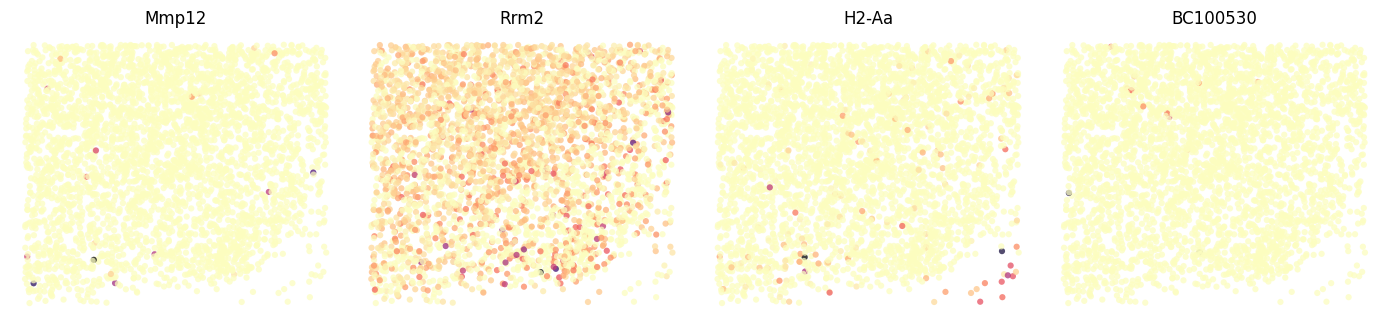

In [6]:
plot_zoom_gene_strip(
    REGION_BOUNDS,
    ["Mmp12","Rrm2","H2-Aa","BC100530"],
    "region1_zoom_gene_expression.png",
)

In [ ]:
mask = zoom_mask(REGION_BOUNDS)
summary = pd.DataFrame({
    "metric": ["n_cells", "mean_total_curvature", "mean_steer_curvature", "mean_surface_curvature", "mean_flow_acceleration", "mean_steer_acceleration", "mean_surface_acceleration"],
    "value": [
        int(mask.sum()),
        float(np.nanmean(k_total[mask])),
        float(np.nanmean(k_steer[mask])),
        float(np.nanmean(k_surface[mask])),
        float(np.nanmean(A_flow[mask])),
        float(np.nanmean(A_steer[mask])),
        float(np.nanmean(A_surface[mask])),
    ],
})
summary.to_csv(FIG_DIR / "region1_curvature_summary.csv", index=False)
summary